# Задача

Обучить модель отличать гамма-события от адронного фона по характеристикам изображений, полученных телескопом MAGIC. Для этого проведём анализ данных, сравним алгоритмы классификации и проверим влияние балансировки классов.


При взаимодействии космических частиц с атмосферой возникают атмосферные ливни. Черенковский телескоп MAGIC регистрирует излучение, по изображению которого можно судить о типе первичной частицы.

В датасете представлены результаты моделирования методом Монте-Карло. В качестве признаков используются параметры формы и положения изображения: `fLength`, `fWidth`, `fSize`, `fConc`, `fConc1` и другие. Класс `g` — гамма-событие (сигнал), `h` — адрон (фон).

[Источник данных — MAGIC Gamma Telescope, UCI](https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope).


# 1. Подгружаем необходимые библиотеки


In [14]:
%pip install -q ucimlrepo imbalanced-learn xgboost lightgbm catboost

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, RocCurveDisplay)
RANDOM_STATE = 42



# 2. Загружаем данные



In [16]:
dataset = fetch_ucirepo(id=159)
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.iloc[:, 0].copy()
print('Размер признаков:', X_raw.shape)
print('Названия признаков:', X_raw.columns.tolist())
print('Классы:', y_raw.value_counts(dropna=False).to_dict())
display(X_raw.head())

Размер признаков: (19020, 10)
Названия признаков: ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist']
Классы: {'g': 12332, 'h': 6688}


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620


# 3. Анализ данных

Проверим пропуски, повторяющиеся строки и основные статистические характеристики. Затем посмотрим на распределение классов и взаимосвязи признаков.


In [17]:
print('Типы столбцов:')
display(X_raw.dtypes.to_frame('dtype'))
print('Пропуски:')
display(X_raw.isna().sum().to_frame('missing'))
print('Повторяющиеся полные строки:', pd.concat([X_raw, y_raw.rename('class')],axis=1).duplicated().sum())
display(X_raw.describe().T)

Типы столбцов:


,dtype
fLength,float64
fWidth,float64
fSize,float64
fConc,float64
fConc1,float64
fAsym,float64
fM3Long,float64
fM3Trans,float64
fAlpha,float64
fDist,float64


Пропуски:


,missing
fLength,0
fWidth,0
fSize,0
fConc,0
fConc1,0
fAsym,0
fM3Long,0
fM3Trans,0
fAlpha,0
fDist,0


Повторяющиеся полные строки: 115


,count,mean,std,min,25%,50%,75%,max
fLength,19020.0,53.250154,42.364855,4.2835,24.336000,37.14770,70.122175,334.1770
fWidth,19020.0,22.180966,18.346056,0.0000,11.863800,17.13990,24.739475,256.3820
fSize,19020.0,2.825017,0.472599,1.9413,2.477100,2.73960,3.101600,5.3233
fConc,19020.0,0.380327,0.182813,0.0131,0.235800,0.35415,0.503700,0.8930
fConc1,19020.0,0.214657,0.110511,0.0003,0.128475,0.19650,0.285225,0.6752
fAsym,19020.0,-4.331745,59.206062,-457.9161,-20.586550,4.01305,24.063700,575.2407
fM3Long,19020.0,10.545545,51.000118,-331.7800,-12.842775,15.31410,35.837800,238.3210
fM3Trans,19020.0,0.249726,20.827439,-205.8947,-10.849375,0.66620,10.946425,179.8510
fAlpha,19020.0,27.645707,26.103621,0.0000,5.547925,17.67950,45.883550,90.0000
fDist,19020.0,193.818026,74.731787,1.2826,142.492250,191.85145,240.563825,495.5610


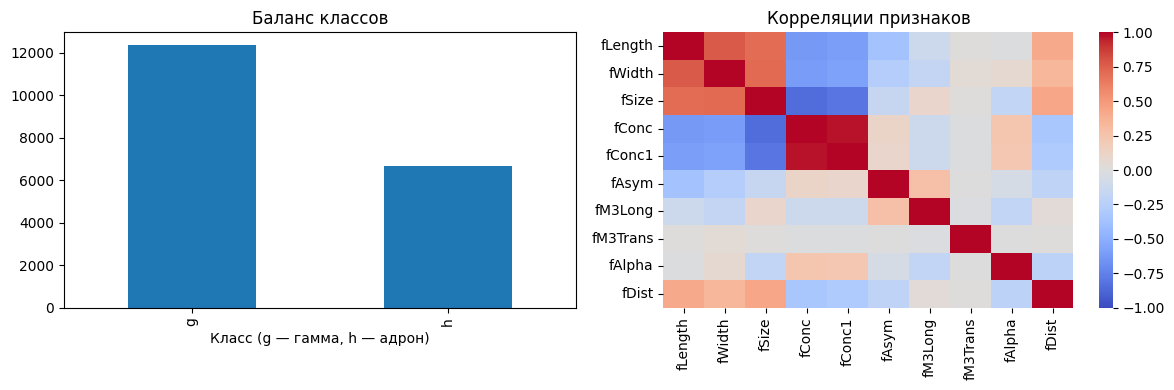

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_raw.value_counts().plot.bar(ax=axes[0], title='Баланс классов')
axes[0].set_xlabel('Класс (g — гамма, h — адрон)')
sns.heatmap(X_raw.corr(numeric_only=True), cmap='coolwarm', center=0,
            vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Корреляции признаков')
plt.tight_layout()
plt.show()

Пропущенных значений нет, но обнаружено 115 повторяющихся строк. Пока оставим их, поскольку по одним только признакам нельзя определить, относятся ли такие записи к одному и тому же событию.

Между `fConc` и `fConc1` заметна сильная корреляция. Позже сравним качество модели с этим признаком и без него.


# 4. Разделение данных

Оставим 20% выборки для тестирования. Гамма-события обозначим числом 1, адроны — 0. Масштабирование выполним только по обучающим данным, чтобы не использовать информацию из тестовой выборки.


In [19]:
X = X_raw.copy()
y = y_raw.astype(str).str.strip().str.lower().map({'g': 1, 'h': 0})
assert y.notna().all(), f'Неизвестные классы: {y_raw.unique()}'
X_train, X_test, y_train, y_test = train_test_split(
    X, y.astype(int), test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Доля гамма-событий train:', round(y_train.mean(), 3))

Train: (15216, 10) | Test: (3804, 10)
Доля гамма-событий train: 0.648


# 5. Обучение моделей

Сравним SVM, Decision Tree, Random Forest, XGBoost, LightGBM и CatBoost. Дополнительно оставим Logistic Regression и простую Baseline-модель, которая всегда выбирает самый частый класс.

Для SVM и Logistic Regression используем стандартизацию. Качество проверим пятикратной кросс-валидацией по Accuracy, Precision, Recall, F1 и ROC-AUC. При сравнении будем ориентироваться прежде всего на F1 для гамма-событий.


In [20]:
models = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1500, random_state=RANDOM_STATE))
    ]),
    'SVM': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(min_samples_leaf=2, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                         random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'XGBoost': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=5,
                                eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'LightGBM': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', LGBMClassifier(n_estimators=150, learning_rate=0.1, num_leaves=31,
                                 random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1))
    ]),
    'CatBoost': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', CatBoostClassifier(iterations=150, depth=6, learning_rate=0.1,
                                     random_seed=RANDOM_STATE, verbose=False,
                                     thread_count=-1))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'precision': 'precision',
           'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=scoring, n_jobs=1)
    row = {'model': name}
    for metric in scoring:
        values = scores['test_' + metric]
        row[metric + '_mean'] = values.mean()
        row[metric + '_std'] = values.std()
    rows.append(row)

cv_results = pd.DataFrame(rows).sort_values('f1_mean', ascending=False)
cv_table = cv_results[['model', 'accuracy_mean', 'precision_mean', 'recall_mean',
                       'f1_mean', 'roc_auc_mean']].copy()
cv_table.columns = ['Модель', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
display(cv_table.round(4))

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
6,LightGBM,0.8814,0.8835,0.9413,0.9115,0.9356
5,XGBoost,0.8791,0.8791,0.9432,0.9100,0.9335
7,CatBoost,0.8770,0.8736,0.9474,0.9090,0.9311
4,Random Forest,0.8778,0.8800,0.9396,0.9088,0.9333
2,SVM,0.8680,0.8567,0.9565,0.9038,0.9151
3,Decision Tree,0.8103,0.8656,0.8374,0.8512,0.8183
1,Logistic Regression,0.7934,0.8054,0.8984,0.8494,0.8413
0,Baseline,0.6484,0.6484,1.0000,0.7867,0.5000


# 6. Балансировка классов

Гамма-событий в выборке больше, чем адронов. Проверим на примере Random Forest, как это влияет на результаты. Сравним обычную модель, модель с весами классов и SMOTE.

SMOTE создаёт дополнительные примеры меньшего класса. Применим его только внутри обучающей части каждого разбиения, чтобы избежать утечки данных.


In [21]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import make_scorer

print('Количество объектов каждого класса:')
print(y_train.map({0: 'Адроны', 1: 'Гамма'}).value_counts())
print()
print('Доля каждого класса:')
print(y_train.map({0: 'Адроны', 1: 'Гамма'}).value_counts(normalize=True).round(3))



Количество объектов каждого класса:
class
Гамма     9866
Адроны    5350
Name: count, dtype: int64

Доля каждого класса:
class
Гамма     0.648
Адроны    0.352
Name: proportion, dtype: float64


In [22]:
# Параметры Random Forest оставляем одинаковыми во всех экспериментах.
rf_params = dict(n_estimators=150, min_samples_leaf=2,
                 random_state=RANDOM_STATE, n_jobs=-1)

balance_models = {
    'Без балансировки': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(**rf_params))
    ]),
    'Веса классов': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(**rf_params, class_weight='balanced'))
    ]),
    'SMOTE': ImbPipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', RandomForestClassifier(**rf_params))
    ])
}

# Отдельно считаем Recall для гамма и адронов.
balance_scoring = {
    'accuracy': 'accuracy',
    'precision_gamma': 'precision',
    'recall_gamma': 'recall',
    'recall_hadron': make_scorer(recall_score, pos_label=0),
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

balance_rows = []
for name, model in balance_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=balance_scoring, n_jobs=1)
    row = {'Вариант': name}
    for metric in balance_scoring:
        row[metric] = scores['test_' + metric].mean()
    balance_rows.append(row)

balance_results = pd.DataFrame(balance_rows).sort_values('f1', ascending=False)
balance_table = balance_results[['Вариант', 'f1', 'roc_auc',
                                 'recall_gamma', 'recall_hadron']].copy()
balance_table.columns = ['Вариант', 'F1 (гамма)', 'ROC-AUC',
                         'Recall (гамма)', 'Recall (адроны)']
display(balance_table.round(4))

,Вариант,F1 (гамма),ROC-AUC,Recall (гамма),Recall (адроны)
0,Без балансировки,0.9088,0.9333,0.9396,0.7637
1,Веса классов,0.9073,0.9333,0.9342,0.7695
2,SMOTE,0.8990,0.9315,0.9000,0.8118


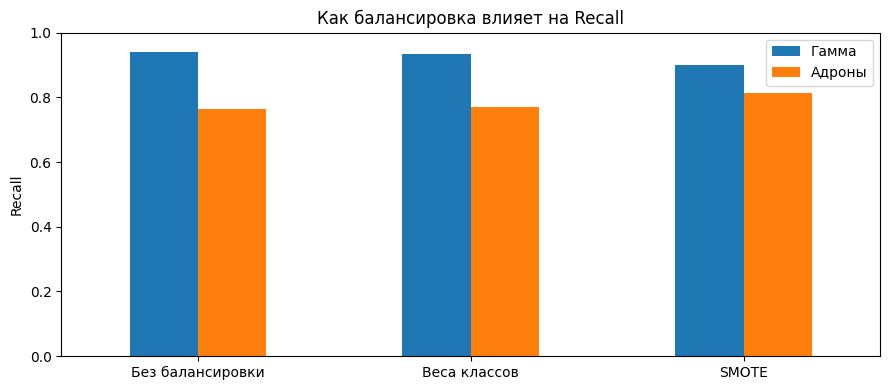

In [23]:
balance_results.set_index('Вариант')[['recall_gamma', 'recall_hadron']].plot.bar(
    figsize=(9, 4), rot=0)
plt.title('Как балансировка влияет на Recall')
plt.ylabel('Recall')
plt.xlabel('')
plt.ylim(0, 1)
plt.legend(['Гамма', 'Адроны'])
plt.tight_layout()
plt.show()

SMOTE повысил Recall адронов с 0.7637 до 0.8118 — значит, меньше адронов ошибочно принимается за гамма-события. Однако Recall гамма-событий снизился с 0.9396 до 0.9000, а F1 тоже уменьшился. Балансировка улучшила распознавание меньшего класса, но не дала прироста F1 для гамма-событий.


# 7. Корреляция признаков

Проверим, влияет ли удаление `fConc1` на качество Logistic Regression. Сравним F1 по кросс-валидации со всеми признаками и без него.


In [24]:
if 'fConc1' in X_train.columns:
    candidate = models['Logistic Regression']
    full_scores = cross_validate(candidate, X_train, y_train, cv=cv, scoring='f1')['test_score']
    drop_scores = cross_validate(candidate, X_train.drop(columns=['fConc1']), y_train,
                                 cv=cv, scoring='f1')['test_score']
    print(f'Все признаки, CV F1: {full_scores.mean():.4f} ± {full_scores.std():.4f}')
    print(f'Без fConc1, CV F1:  {drop_scores.mean():.4f} ± {drop_scores.std():.4f}')
else:
    print('Признак fConc1 не найден: проверь названия столбцов.')

Все признаки, CV F1: 0.8494 ± 0.0044
Без fConc1, CV F1:  0.8487 ± 0.0040


# 8. Проверка на тестовой выборке

Выберем модель с наибольшим средним F1 на кросс-валидации. Затем проверим её на тестовой выборке, построим матрицу ошибок и ROC-кривую.


Лучшая модель по CV F1: LightGBM
              precision    recall  f1-score   support

  hadron (0)       0.89      0.79      0.84      1338
   gamma (1)       0.89      0.95      0.92      2466

    accuracy                           0.89      3804
   macro avg       0.89      0.87      0.88      3804
weighted avg       0.89      0.89      0.89      3804

ROC AUC: 0.9425


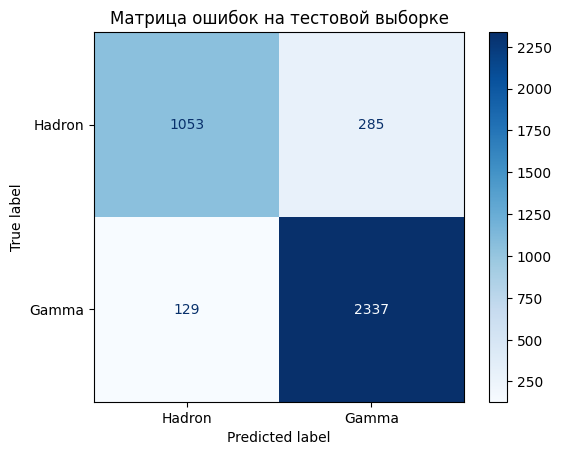

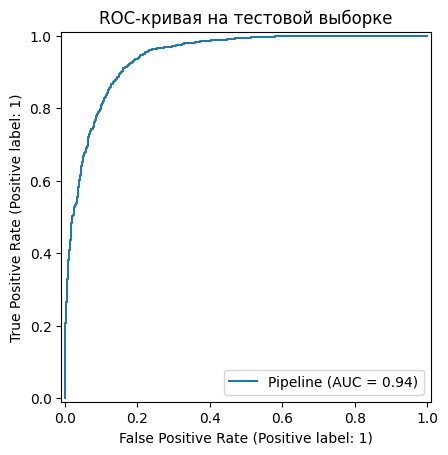

In [25]:
candidate_scores = {row['model']: row['f1_mean'] for _, row in cv_results.iterrows()}
candidate_models = dict(models)
for name, model in balance_models.items():
    full_name = 'Random Forest — ' + name
    candidate_scores[full_name] = float(balance_results.loc[
        balance_results['Вариант'] == name, 'f1'].iloc[0])
    candidate_models[full_name] = model

best_name = max(candidate_scores, key=candidate_scores.get)
best_model = candidate_models[best_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print('Лучшая модель по CV F1:', best_name)
print(classification_report(y_test, y_pred,
      target_names=['hadron (0)', 'gamma (1)'], zero_division=0))
print('ROC AUC:', round(roc_auc_score(y_test,
      best_model.predict_proba(X_test)[:, 1]), 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
      display_labels=['Hadron', 'Gamma'], cmap='Blues')
plt.title('Матрица ошибок на тестовой выборке')
plt.show()
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title('ROC-кривая на тестовой выборке')
plt.show()

# Вывод

В работе использован набор MAGIC Gamma Telescope: 19 020 событий и 10 числовых признаков. Пропущенных значений нет, обнаружено 115 повторяющихся строк. Гамма-события составляют 64.8% выборки, адроны — 35.2%.

Были рассмотрены шесть алгоритмов из задания, а также Logistic Regression и Baseline. Наибольший средний F1 при кросс-валидации показал **LightGBM — 0.9115**. Его ROC-AUC составил **0.9356**. Близкие результаты получили XGBoost, CatBoost и Random Forest, поэтому разница между ними не выглядит существенной без дополнительной проверки.

На тестовой выборке LightGBM показал Accuracy около **89.1%** и ROC-AUC **0.9425**. По матрице ошибок правильно распознаны 2337 гамма-событий и 1053 адрона. При этом 285 адронов были ошибочно отнесены к гамма-событиям, а 129 гамма-событий — к адронам. Таким образом, модель лучше обнаруживает гамма-события, чем отделяет адронный фон.

Отдельно проверили балансировку на Random Forest. При использовании SMOTE Recall адронов вырос с 0.7637 до 0.8118, но Recall гамма-событий снизился с 0.9396 до 0.9000. По F1 обычный Random Forest оказался лучше варианта со SMOTE. Выбор способа балансировки зависит от того, какие ошибки для задачи критичнее.

Также проверили удаление `fConc1`, сильно коррелирующего с `fConc`. Для Logistic Regression F1 практически не изменился: 0.8494 со всеми признаками и 0.8487 без `fConc1`.

**Ограничения:** датасет получен при моделировании методом Монте-Карло, а не при обработке реальных наблюдений. В нём имеются повторяющиеся строки, которые мы не можем уверенно отнести к одним и тем же событиям.
